# 2. Data Science with Scikit-Learn: Pipelines for Time Series/non iid

### Topics:
**`sklearn` Paradigm**: `BaseEstimator`, `TransformerMixin`, and `RegressorMixin`.

**Custom Transformers**:
* `SensorClipper`: Cutting impossible sensor spikes (domain physics).
* `ForwardFillImputer`: Fills missing values (`NaN`) using previous valid measurements without future leakage.

**Custom Estimator**: Wrapping `statsmodels.tsa.arima.model.ARIMA` into an `sklearn`-compatible estimator.

**The `Pipeline`**: Chaining data cleaning, imputation, and forecasting into a pipeline.

**Validation**: How to use `TimeSeriesSplit`.

**Evaluation & Visualization**

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, TransformerMixin, RegressorMixin
from sklearn.pipeline import Pipeline
from sklearn.model_selection import TimeSeriesSplit
from sklearn.metrics import root_mean_squared_error, mean_absolute_error

from statsmodels.tsa.arima.model import ARIMA
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning
warnings.filterwarnings('ignore', category=ConvergenceWarning)
warnings.filterwarnings('ignore', category=UserWarning)

np.random.seed(42)
print("imports rdy")

imports rdy


## 2.1 Generating Realistic Time-Series Sensor Data

Sensor data typically exhibits:
- Underlying autoregressive dynamics ($	\text{AR}(1)$ / $\text{ARMA}(1, 1)$) + 24h periodicity.
- **Impossible physical readings** (e.g., negative readings from a flow/pressure sensor, or spike voltages $> 100$).
- **Missing data (`NaN`s)** caused by transmission packet dropouts.

In [17]:
# 1. Simulate an AR(1) process with seasonal diurnal variation
n_samples = 400
t = np.arange(n_samples)

# AR(1) recurrence: y_t = 0.7 * y_{t-1} + noise
phi = 0.75
ar_series = np.zeros(n_samples)
noise = np.random.normal(0, 1.0, size=n_samples)
for i in range(1, n_samples):
    ar_series[i] = phi * ar_series[i - 1] + noise[i]

day_cycle = 4.0 * np.sin(2 * np.pi * t / 24)
baseline = 20.0
clean_target = baseline + day_cycle + ar_series

# 2. Create contaminated sensor series: inject missing values (NaNs) and impossible spikes
corrupted_series = clean_target.copy()

nan_indices = np.random.choice(np.arange(10, n_samples - 10), size=20, replace=False)
corrupted_series[nan_indices] = np.nan

corrupted_series[50] = 95.0   
corrupted_series[180] = -35.0 
corrupted_series[310] = 88.0  

df = pd.DataFrame({
    'time_step': t,
    'sensor_value': corrupted_series
})

print(f"Total samples: {len(df)}")
print(f"Missing values (NaNs): {df['sensor_value'].isna().sum()}")
print(f"Values outside valid range [0, 45]: {((df['sensor_value'] < 0) | (df['sensor_value'] > 45)).sum()}")

Total samples: 400
Missing values (NaNs): 20
Values outside valid range [0, 45]: 3


## 2.2 The Scikit-Learn Paradigm: Custom Transformers

In `scikit-learn`, every data tranformer is structured like this:
- `fit(X, y=None)`: Computes and stores parameters from training array. (Must return `self`)
- `transform(X)`: Applies transformation and returns the processed matrix/array.
- By inheriting from `BaseEstimator` and `TransformerMixin`, we automatically get `fit_transform()` and hyperparameter inspection for free!

Let's build two domain-specific transformers:
1. `SensorClipper`: Clips impossible values to $[min\_val, max\_val]$.
2. `ForwardFillImputer`: Imputes missing values by choosing last availabe value in time.

In [18]:
class SensorClipper(BaseEstimator, TransformerMixin):
    """Clips sensor values to a physiologically or physically valid range [min_val, max_val]."""
    def __init__(self, min_val=0.0, max_val=45.0):
        self.min_val = min_val
        self.max_val = max_val
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_out = np.asarray(X, dtype=float).copy()
        
        X_out[X_out < self.min_val] = self.min_val
        X_out[X_out > self.max_val] = self.max_val
        
        return X_out


class ForwardFillImputer(BaseEstimator, TransformerMixin):
    """
    Imputes missing values (NaN) using the last observed valid entry (forward-fill).
    """
    def __init__(self, default_fill=0.0):
        self.default_fill = default_fill
        self.learned_initial_val_ = None
        
    def fit(self, X, y=None):
        return self
        
    def transform(self, X):
        X_arr = np.asarray(X, dtype=float).copy()
        
        # Forward fill along time axis
        s = pd.Series(X_arr.ravel())
        s_imputed = s.ffill()
        
        return s_imputed.to_numpy().reshape(X_arr.shape)

### Quick Sanity Check: Test the Transformers in Isolation

In [19]:
# Test on corrupted series
sample_raw = df['sensor_value'].values
clipper = SensorClipper(min_val=0.0, max_val=45.0)
imputer = ForwardFillImputer()

cleaned_clipped = clipper.fit_transform(sample_raw)
cleaned_full = imputer.fit_transform(cleaned_clipped)

print(f"Raw NaNs: {np.isnan(sample_raw).sum():.1f} -> Imputed NaNs: {np.isnan(cleaned_full).sum():.1f}")
print(f"Raw Max:  {np.nanmax(sample_raw):.1f} -> Clipped Max:  {np.nanmax(cleaned_full):.1f}")
print(f"Raw Min: {np.nanmin(sample_raw):.1f} -> Clipped Min:  {np.nanmin(cleaned_full):.1f}")

Raw NaNs: 20.0 -> Imputed NaNs: 0.0
Raw Max:  95.0 -> Clipped Max:  45.0
Raw Min: -35.0 -> Clipped Min:  0.0


## 2.3 Custom Estimator: Wrapping `statsmodels` ARMA into Scikit-Learn

`statsmodels` has powerful time-series models like `ARIMA`, but its API differs from `scikit-learn` (`fit()` returns a `Results` object rather than `self`).

To put `statsmodels` into an `sklearn.pipeline.Pipeline`, we inherit from `BaseEstimator` and `RegressorMixin` and wrap `ARIMA(p, d, q)`.

In [20]:
class StatsmodelsARMAEstimator(BaseEstimator, RegressorMixin):
    """
    Scikit-learn compatible wrapper around statsmodels.tsa.arima.model.ARIMA.
    """
    def __init__(self, order=(1, 0, 1)):
        self.order = order
        self.model_res_ = None
        self.fitted_y_ = None
        
    def fit(self, X, y=None):
        # For univariate time series, X or y contains the series values
        data = y if y is not None else X
        series = np.asarray(data, dtype=float).ravel()
        
        # Fit statsmodels ARIMA
        model = ARIMA(series, order=self.order)
        self.model_res_ = model.fit()
        self.fitted_y_ = self.model_res_.fittedvalues
        return self
        
    def predict(self, X):
        """Forecast steps corresponding to the length of test segment X."""
        n_steps = len(X)
        forecast_res = self.model_res_.forecast(steps=n_steps)
        return np.asarray(forecast_res)

## 2.4 Composing the Scikit-Learn `Pipeline`

The pipeline chains preprocessing and estimator together into an atomic unit:
$$\text{Raw Sensor Data} \xrightarrow{\text{SensorClipper}} \text{Clipped Data} \xrightarrow{\text{ForwardFillImputer}} \text{Clean Data} \xrightarrow{\text{ARMA}} \text{Forecast}$$

In [21]:
ts_pipeline = Pipeline([
    ('clipper', SensorClipper(min_val=0.0, max_val=45.0)),
    ('imputer', ForwardFillImputer()),
    ('arma_model', StatsmodelsARMAEstimator(order=(2, 0, 1)))
])

print("Constructed Pipeline:")
print(ts_pipeline)

Constructed Pipeline:
Pipeline(steps=[('clipper', SensorClipper()), ('imputer', ForwardFillImputer()),
                ('arma_model', StatsmodelsARMAEstimator(order=(2, 0, 1)))])


## 2.5 Time-Series Cross-Validation (`TimeSeriesSplit`)

### Why standard K-Fold is wrong for Time Series:
Standard K-Fold randomly shuffles samples into intervalls. In time-series data, this causes **severe lookahead bias (data leakage)**: predicting $y_t$ using information from $y_{t+5}$!

`TimeSeriesSplit` provides an expanding training window where training always strictly precedes testing.

In [1]:
# Visualize TimeSeriesSplit folds
n_splits = 4
tscv = TimeSeriesSplit(n_splits=n_splits, test_size=40)

fig, ax = plt.subplots(figsize=(10, 3.5))
for fold_idx, (train_idx, test_idx) in enumerate(tscv.split(df['sensor_value'])):
    ax.scatter(train_idx, [fold_idx] * len(train_idx), color='tab:blue', marker='_', lw=6, label='Train' if fold_idx == 0 else "")
    ax.scatter(test_idx, [fold_idx] * len(test_idx), color='tab:orange', marker='_', lw=6, label='Test' if fold_idx == 0 else "")

ax.set_yticks(range(n_splits))
ax.set_yticklabels([f"Fold {i+1}" for i in range(n_splits)])
ax.set_xlabel("Time Step Index")
ax.set_title("Expanding Window TimeSeriesSplit (No Future Lookahead)")
ax.legend(loc='upper left')
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'TimeSeriesSplit' is not defined

## 2.6 Running the Cross-Validation Loop & Evaluating Performance

In [23]:
metrics = []
predictions_per_fold = []

y_raw = df['sensor_value'].values

for fold, (train_idx, test_idx) in enumerate(tscv.split(y_raw)):
    y_train = y_raw[train_idx]
    y_test = y_raw[test_idx]
    
    # 1. Fit entire pipeline strictly on training fold
    ts_pipeline.fit(y_train)
    
    # 2. Predict on test fold horizon
    y_pred = ts_pipeline.predict(y_test)
    
    # 3. Clean test ground truth for fair evaluation (clip spikes/fill test NaNs for ground truth reference)
    y_test_clean = np.asarray(pd.Series(np.clip(y_test, 0.0, 45.0)).ffill().bfill())
    
    fold_rmse = root_mean_squared_error(y_test_clean, y_pred)
    fold_mae = mean_absolute_error(y_test_clean, y_pred)
    
    metrics.append({"Fold": fold + 1, "RMSE": fold_rmse, "MAE": fold_mae, "Test Size": len(test_idx)})
    predictions_per_fold.append((test_idx, y_test_clean, y_pred))

metrics_df = pd.DataFrame(metrics)
print("=== Cross-Validation Results ===")
print(metrics_df.to_string(index=False))
print(f"\nMean RMSE: {metrics_df['RMSE'].mean():.2f} ± {metrics_df['RMSE'].std():.2f}")
print(f"Mean MAE:  {metrics_df['MAE'].mean():.2f} ± {metrics_df['MAE'].std():.2f}")

=== Cross-Validation Results ===
 Fold     RMSE      MAE  Test Size
    1 2.880354 2.642171         40
    2 4.991895 3.228884         40
    3 2.706440 2.437819         40
    4 3.164019 2.770978         40

Mean RMSE: 3.44 ± 1.05
Mean MAE:  2.77 ± 0.34


## 2.7 Visualizing Model Predictions vs. Ground Truth

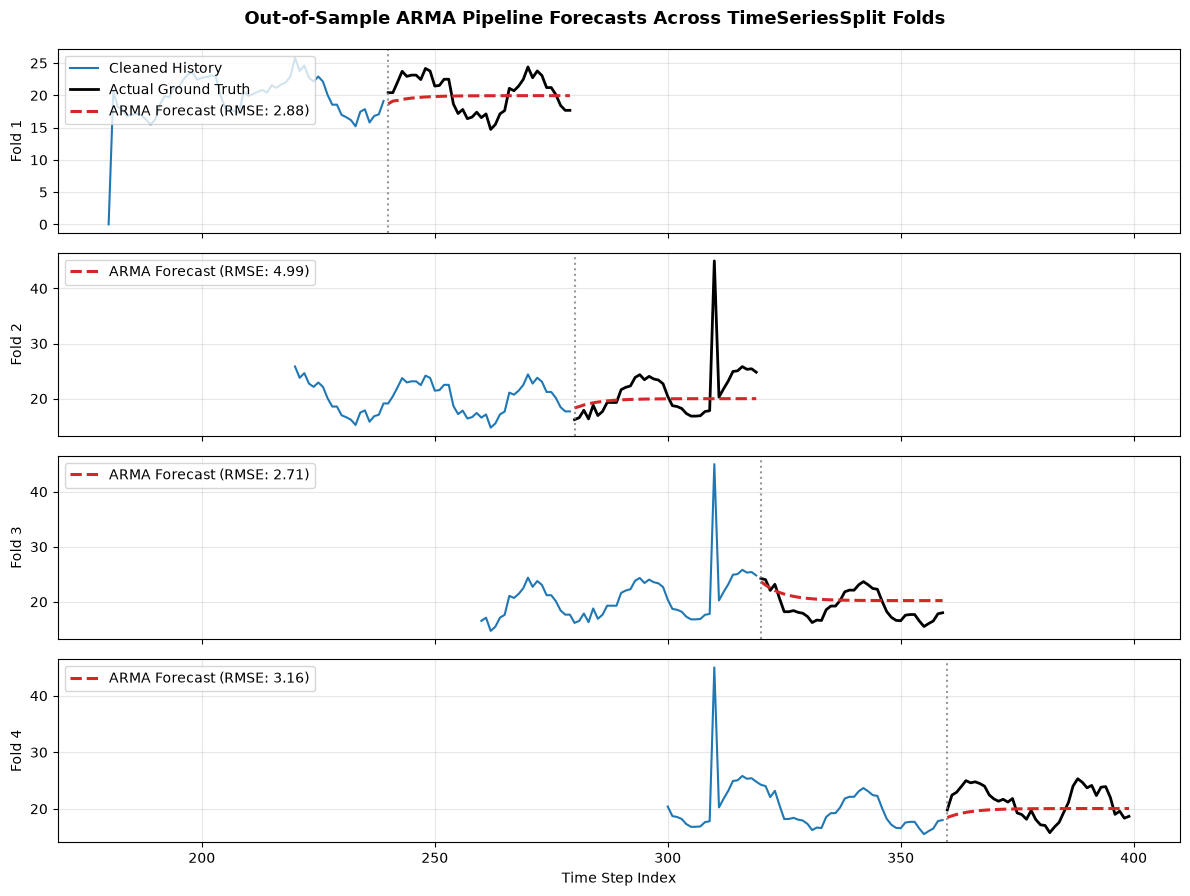

In [24]:
fig, axes = plt.subplots(n_splits, 1, figsize=(12, 9), sharex=True)

# Also get fully cleaned series for visual comparison
clean_reference = imputer.fit_transform(clipper.fit_transform(y_raw))

for fold, (test_idx, y_test_clean, y_pred) in enumerate(predictions_per_fold):
    ax = axes[fold]
    
    # Plot recent history before test fold
    history_start = max(0, test_idx[0] - 60)
    ax.plot(range(history_start, test_idx[0]), clean_reference[history_start:test_idx[0]], 
            color='tab:blue', label="Cleaned History" if fold == 0 else "")
    
    # Plot true test signal
    ax.plot(test_idx, y_test_clean, color='black', lw=2, label="Actual Ground Truth" if fold == 0 else "")
    
    # Plot pipeline prediction
    ax.plot(test_idx, y_pred, color='tab:red', linestyle='--', lw=2.2, 
            label=f"ARMA Forecast (RMSE: {metrics_df.loc[fold, 'RMSE']:.2f})" if fold == 0 else f"ARMA Forecast (RMSE: {metrics_df.loc[fold, 'RMSE']:.2f})")
    
    ax.axvline(test_idx[0], color='gray', linestyle=':', alpha=0.8)
    ax.set_ylabel(f"Fold {fold+1}")
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper left')

axes[-1].set_xlabel("Time Step Index")
plt.suptitle("Out-of-Sample ARMA Pipeline Forecasts Across TimeSeriesSplit Folds", fontsize=13, fontweight='bold', y=0.99)
plt.tight_layout()
plt.show()